# Cvičení: Ames Housing Dataset

https://pslib.sharepoint.com/sites/studium/it/uin/SitePages/Ex-Ames-Housing.aspx?TeamsCID=7c2ce885-f32a-49e7-8ce1-3a585ad1895e

(2930, 80)
<class 'pandas.core.frame.DataFrame'>
Index: 2930 entries, 1 to 2930
Data columns (total 80 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   MS SubClass      2930 non-null   int64  
 1   MS Zoning        2930 non-null   object 
 2   Lot Frontage     2440 non-null   float64
 3   Lot Area         2930 non-null   int64  
 4   Street           2930 non-null   object 
 5   Alley            198 non-null    object 
 6   Lot Shape        2930 non-null   object 
 7   Land Contour     2930 non-null   object 
 8   Utilities        2930 non-null   object 
 9   Lot Config       2930 non-null   object 
 10  Land Slope       2930 non-null   object 
 11  Neighborhood     2930 non-null   object 
 12  Condition 1      2930 non-null   object 
 13  Condition 2      2930 non-null   object 
 14  Bldg Type        2930 non-null   object 
 15  House Style      2930 non-null   object 
 16  Overall Qual     2930 non-null   int64  
 17  Overall 

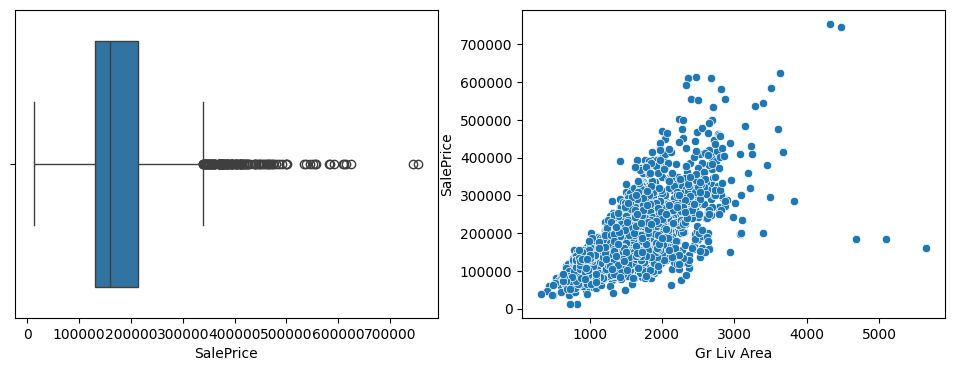

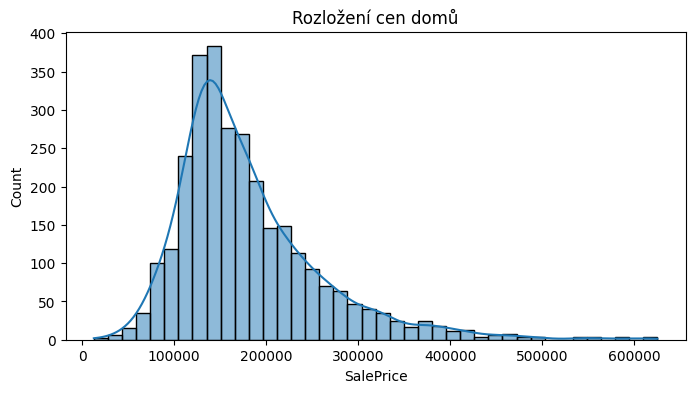

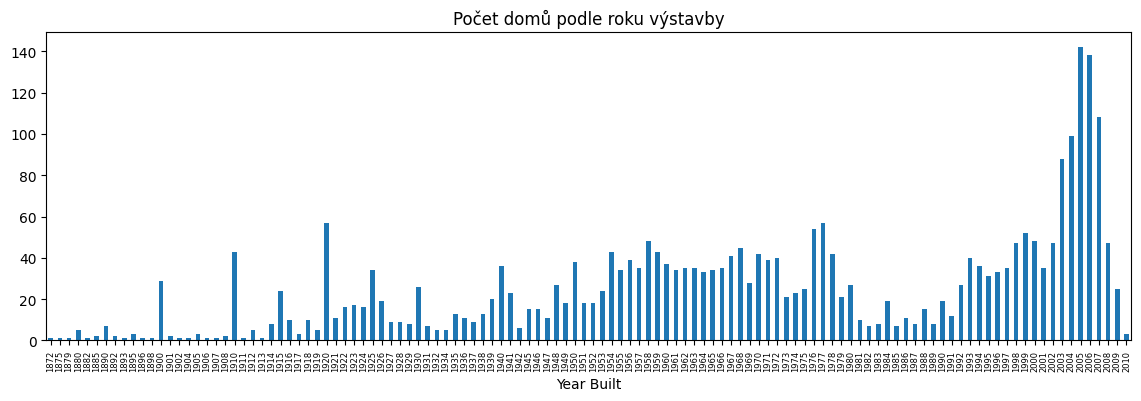

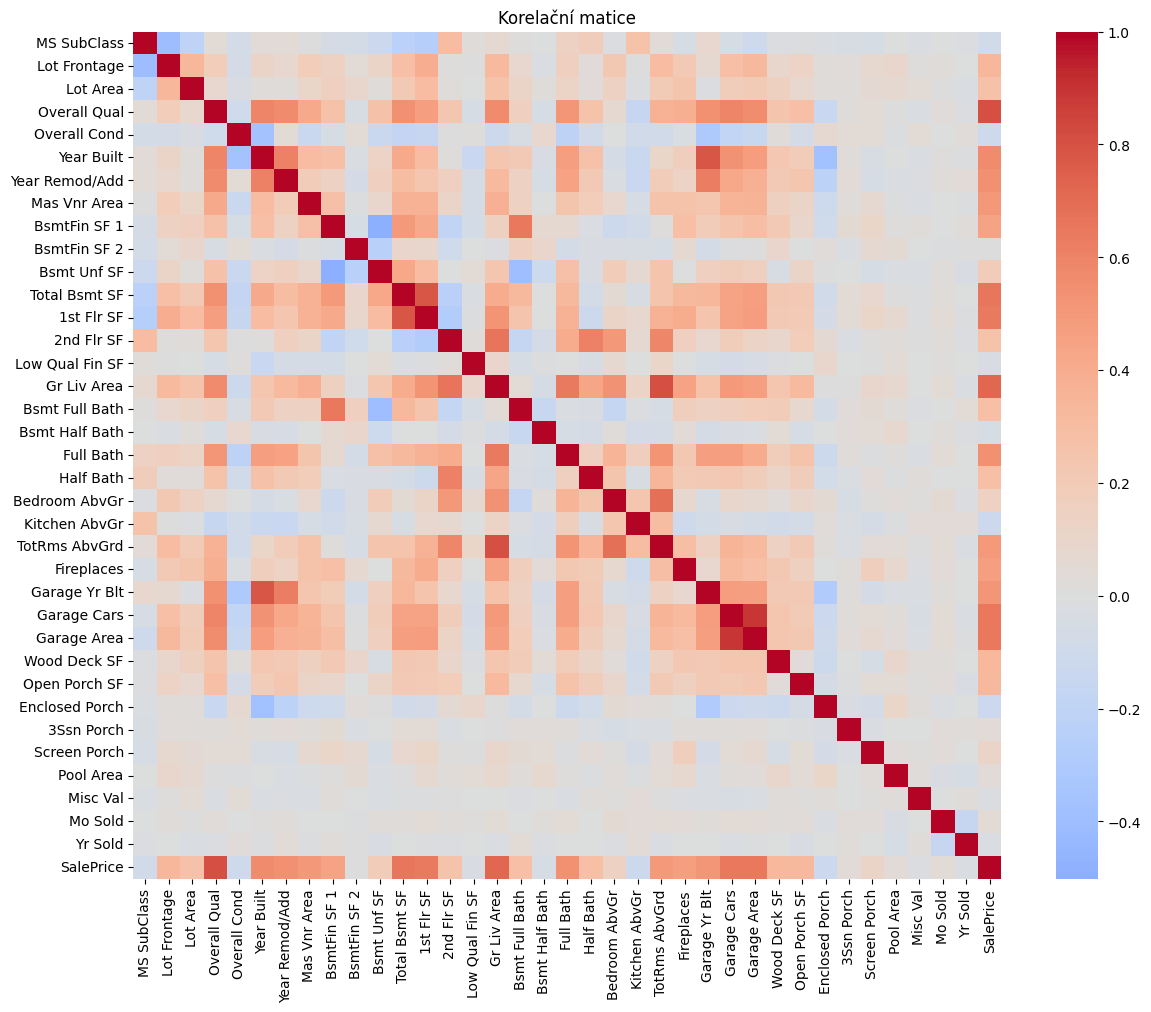

Overall Qual     0.805236
Gr Liv Area      0.719463
Total Bsmt SF    0.658519
Name: SalePrice, dtype: float64
(2925, 75)
<class 'pandas.core.frame.DataFrame'>
Index: 2925 entries, 1 to 2930
Data columns (total 75 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   MS SubClass      2925 non-null   int64  
 1   MS Zoning        2925 non-null   object 
 2   Lot Frontage     2925 non-null   float64
 3   Lot Area         2925 non-null   int64  
 4   Street           2925 non-null   object 
 5   Lot Shape        2925 non-null   object 
 6   Land Contour     2925 non-null   object 
 7   Utilities        2925 non-null   object 
 8   Lot Config       2925 non-null   object 
 9   Land Slope       2925 non-null   object 
 10  Neighborhood     2925 non-null   object 
 11  Condition 1      2925 non-null   object 
 12  Condition 2      2925 non-null   object 
 13  Bldg Type        2925 non-null   object 
 14  House Style      2925 non-null   obj

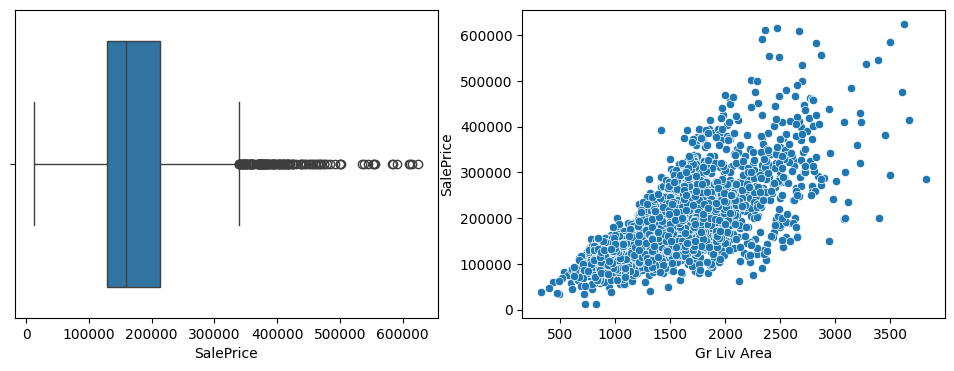

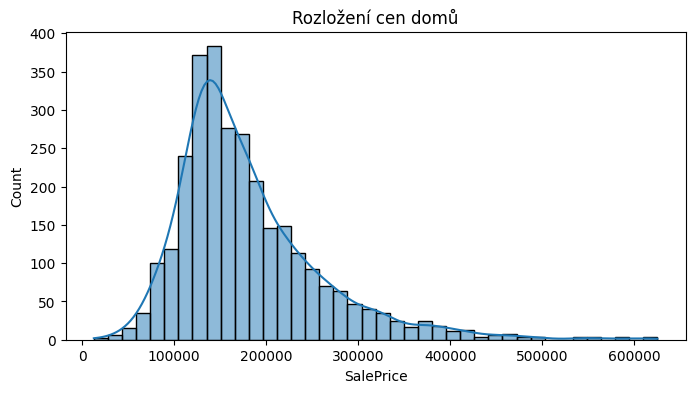

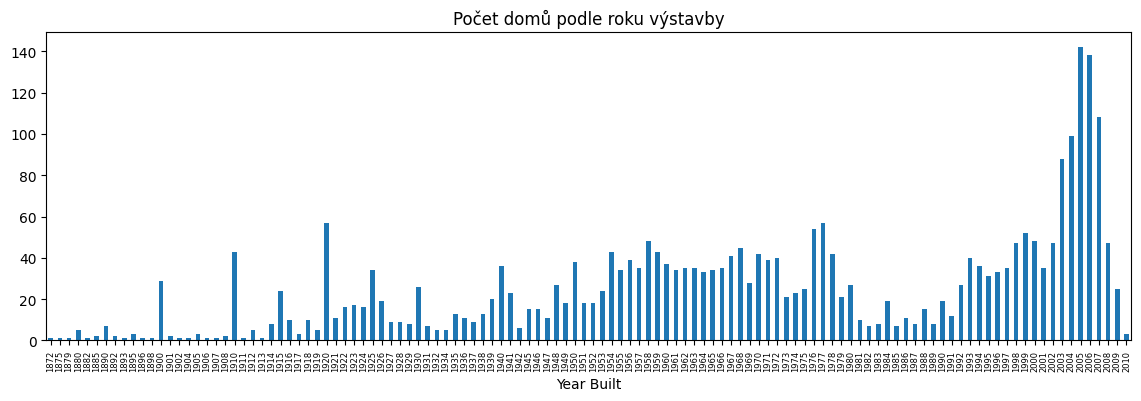

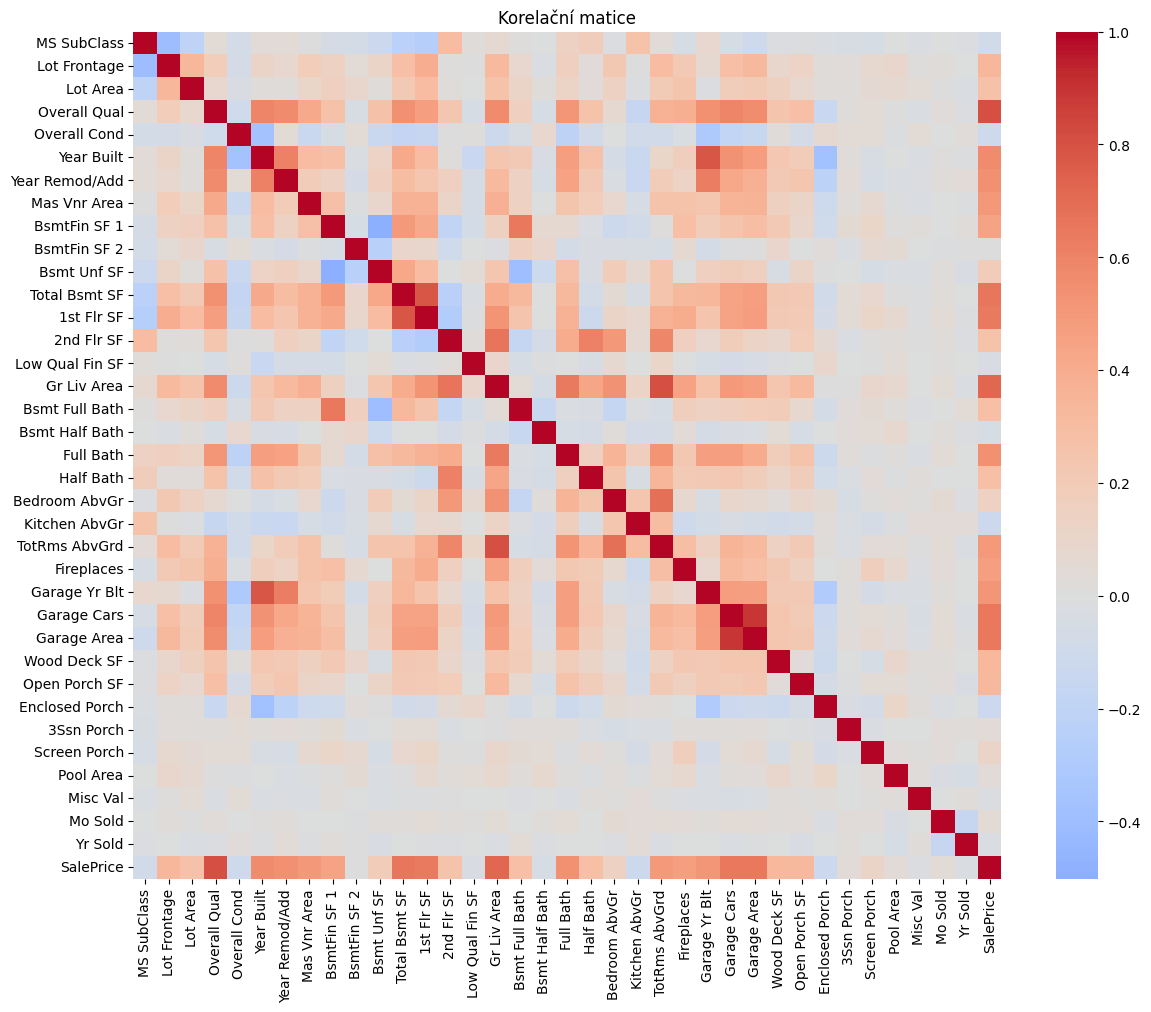

Overall Qual     0.805236
Gr Liv Area      0.719463
Total Bsmt SF    0.658519
Name: SalePrice, dtype: float64


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



df = pd.read_csv("/content/data/AmesHousing(in).csv", encoding="utf-8-sig", index_col=0)  # adjust to the name printed above

df.head(10)




df = df.drop(columns=["index", "Order", "PID"], errors="ignore")

print(df.shape)
df.info()
missing = df.isnull().sum().sort_values(ascending=False)
print(missing[missing > 0])

# 2) Chybějící hodnoty
# Sloupce s >50 % chybějících hodnot (Alley, Pool QC, Fence, Misc Feature) vyhodíme
thr = 0.5 * len(df)
df = df.loc[:, df.isnull().sum() <= thr]

# Numerické -> medián, kategoriální -> modus
for col in df.columns:
    if df[col].isnull().any():
        if df[col].dtype == "object":
            df[col] = df[col].fillna(df[col].mode()[0])
        else:
            df[col] = df[col].fillna(df[col].median())
print("Zbývá chybějících:", df.isnull().sum().sum())

# 3) Odlehlé hodnoty (IQR + boxplot)
q1, q3 = df["SalePrice"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print("Outliery SalePrice (IQR):", ((df["SalePrice"] < low) | (df["SalePrice"] > high)).sum())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df["SalePrice"], ax=ax[0])
sns.scatterplot(x="Gr Liv Area", y="SalePrice", data=df, ax=ax[1])
plt.show()

# Odstraníme jen zjevné extrémy (velké domy za podezřele nízkou cenu)
df = df[df["Gr Liv Area"] < 4000]

# 4) Grafy
plt.figure(figsize=(8, 4))
sns.histplot(df["SalePrice"], bins=40, kde=True)
plt.title("Rozložení cen domů")
plt.show()

plt.figure(figsize=(14, 4))
df["Year Built"].value_counts().sort_index().plot(kind="bar")
plt.title("Počet domů podle roku výstavby")
plt.xticks(rotation=90, fontsize=6)
plt.show()

# 5) Korelace jen pro číselné sloupce
corr = df.select_dtypes(include="number").corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Korelační matice")
plt.show()

top3 = corr["SalePrice"].drop("SalePrice").sort_values(ascending=False).head(3)
print(top3)



df = df.drop(columns=["index", "Order", "PID"], errors="ignore")

print(df.shape)
df.info()
missing = df.isnull().sum().sort_values(ascending=False)
print(missing[missing > 0])

# 2) Chybějící hodnoty
# Sloupce s >50 % chybějících hodnot (Alley, Pool QC, Fence, Misc Feature) vyhodíme
thr = 0.5 * len(df)
df = df.loc[:, df.isnull().sum() <= thr]

# Numerické -> medián, kategoriální -> modus
for col in df.columns:
    if df[col].isnull().any():
        if df[col].dtype == "object":
            df[col] = df[col].fillna(df[col].mode()[0])
        else:
            df[col] = df[col].fillna(df[col].median())
print("Zbývá chybějících:", df.isnull().sum().sum())

# 3) Odlehlé hodnoty (IQR + boxplot)
q1, q3 = df["SalePrice"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print("Outliery SalePrice (IQR):", ((df["SalePrice"] < low) | (df["SalePrice"] > high)).sum())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df["SalePrice"], ax=ax[0])
sns.scatterplot(x="Gr Liv Area", y="SalePrice", data=df, ax=ax[1])
plt.show()

# Odstraníme jen zjevné extrémy (velké domy za podezřele nízkou cenu)
df = df[df["Gr Liv Area"] < 4000]

# 4) Grafy
plt.figure(figsize=(8, 4))
sns.histplot(df["SalePrice"], bins=40, kde=True)
plt.title("Rozložení cen domů")
plt.show()

plt.figure(figsize=(14, 4))
df["Year Built"].value_counts().sort_index().plot(kind="bar")
plt.title("Počet domů podle roku výstavby")
plt.xticks(rotation=90, fontsize=6)
plt.show()

# 5) Korelace jen pro číselné sloupce
corr = df.select_dtypes(include="number").corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Korelační matice")
plt.show()

top3 = corr["SalePrice"].drop("SalePrice").sort_values(ascending=False).head(3)
print(top3)